## 1. CARGA Y EXPLORACION

In [1]:
import re, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import nltk
from nltk.corpus import stopwords
from nltk.stem.porter import PorterStemmer

nltk.download('stopwords')

SEED = 42

[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\RAMIRO\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


In [2]:
df = pd.read_csv('IMDB Dataset.csv')
print(df.shape)
df.head()

(50000, 2)


,review,sentiment
0,One of the other reviewers has mentioned that ...,positive
1,A wonderful little production. <br /><br />The...,positive
2,I thought this was a wonderful way to spend ti...,positive
3,Basically there's a family where a little boy ...,negative
4,"Petter Mattei's ""Love in the Time of Money"" is...",positive


sentiment
positive    25000
negative    25000
Name: count, dtype: int64


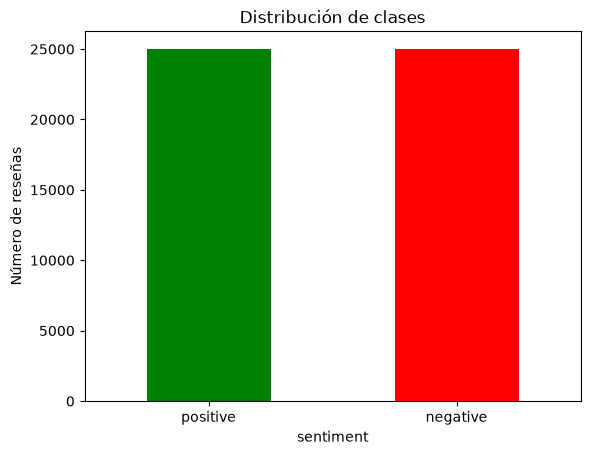

In [3]:
conteo = df['sentiment'].value_counts()
print(conteo)

conteo.plot(kind='bar', color=['green', 'red'], rot=0)
plt.title('Distribución de clases')
plt.ylabel('Número de reseñas')
plt.show()

In [4]:
print('Nulos por columna:')
print(df.isnull().sum())

print('\nFilas duplicadas:', df.duplicated().sum())

Nulos por columna:
review       0
sentiment    0
dtype: int64

Filas duplicadas: 418


In [5]:
df = df.drop_duplicates().reset_index(drop=True)
print(df.shape)
print(df['sentiment'].value_counts())

(49582, 2)
sentiment
positive    24884
negative    24698
Name: count, dtype: int64


**EXPLICACION**

**No hay valores nulos. Hay 418 reseñas duplicadas, que eliminé porque no aportan información y podrían quedar una en entrenamiento y otra en prueba, inflando la exactitud. Después de eliminarlas, las clases siguen casi balanceadas.**

In [6]:
df['n_palabras'] = df['review'].str.split().str.len()
df.groupby('sentiment')['n_palabras'].describe()

,count,mean,std,min,25%,50%,75%,max
sentiment,,,,,,,,
negative,24698.0,229.596607,165.103430,4.0,128.0,174.0,278.0,1522.0
positive,24884.0,233.090620,177.688169,10.0,125.0,172.0,284.0,2470.0


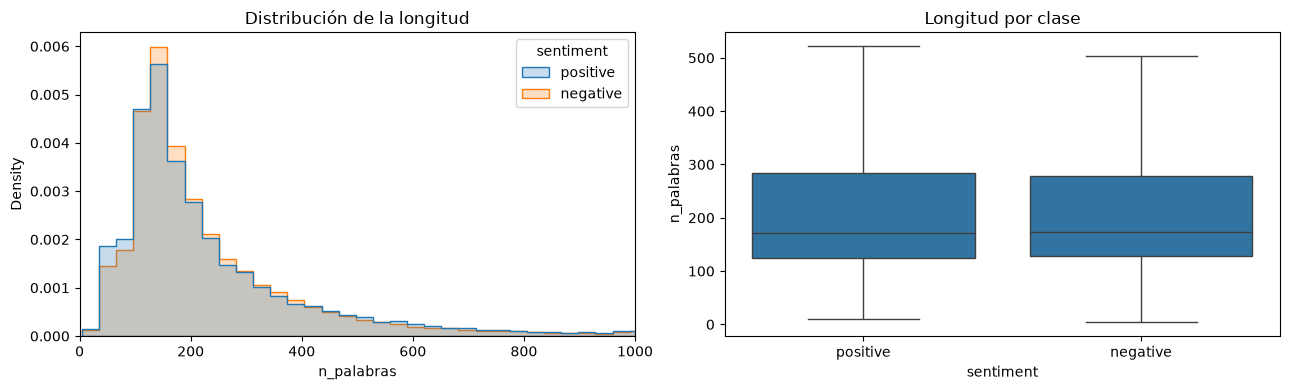

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

sns.histplot(data=df, x='n_palabras', hue='sentiment', bins=80,
             element='step', stat='density', common_norm=False, ax=axes[0])
axes[0].set_xlim(0, 1000)
axes[0].set_title('Distribución de la longitud')

sns.boxplot(data=df, x='sentiment', y='n_palabras', showfliers=False, ax=axes[1])
axes[1].set_title('Longitud por clase')

plt.tight_layout()
plt.show()

**EXPLICACION**

**Las reseñas son largas la mediana es de unas 173 palabras, y hay muchas reseñas extensas que la maxima es de 2470 palabras.**

**Las dos clases tienen distribuciones casi idénticas: las medianas son 174 (negativas) y 172 (positivas), y los histogramas y las cajas prácticamente se superponen. Las positivas tienen algunas reseñas extremadamente largas, por eso su máximo y su promedio son un poco mayores.**


## 2. PREPROCESAMIENTO DEL TEXTO

In [8]:
for i in [0, 1, 7]:
    print(f'--- Reseña {i} ({df.sentiment[i]}) ---')
    print(df.review[i][:700])
    print()

--- Reseña 0 (positive) ---
One of the other reviewers has mentioned that after watching just 1 Oz episode you'll be hooked. They are right, as this is exactly what happened with me.<br /><br />The first thing that struck me about Oz was its brutality and unflinching scenes of violence, which set in right from the word GO. Trust me, this is not a show for the faint hearted or timid. This show pulls no punches with regards to drugs, sex or violence. Its is hardcore, in the classic use of the word.<br /><br />It is called OZ as that is the nickname given to the Oswald Maximum Security State Penitentary. It focuses mainly on Emerald City, an experimental section of the prison where all the cells have glass fronts and face

--- Reseña 1 (positive) ---
A wonderful little production. <br /><br />The filming technique is very unassuming- very old-time-BBC fashion and gives a comforting, and sometimes discomforting, sense of realism to the entire piece. <br /><br />The actors are extremely wel

In [9]:
r = df['review']
patrones = {
    'Etiqueta <br />'       : r'<br\s*/?>',
    'Otras etiquetas HTML'  : r'</?(?:i|p|b|em)>',
    'URLs'                  : r'https?://\S+|www\.\S+',
    'Correos'               : r'\S+@\S+\.\S+',
    "Contracciones n't"     : r"n't\b",
    'Dígitos'               : r'\d',
    'Puntuación'            : r'[^\w\s]',
    'Mayúsculas'            : r'[A-Z]',
}
resumen = pd.DataFrame({'reseñas': {k: r.str.contains(p, regex=True).sum()
                                    for k, p in patrones.items()}})
resumen['%'] = (resumen['reseñas'] / len(r) * 100).round(2)
resumen

,reseñas,%
Etiqueta <br />,28966,58.42
Otras etiquetas HTML,4,0.01
URLs,195,0.39
Correos,47,0.09
Contracciones n't,29279,59.05
Dígitos,27786,56.04
Puntuación,49578,99.99
Mayúsculas,49364,99.56


### Elementos "sucios" encontrados y decisiones de limpieza

Antes de limpiar, inspeccioné varias reseñas y conté cuántas contienen cada tipo de elemento, para **eliminar solo lo que realmente existe**.

| Elemento | ¿Existe? | Decisión |
|---|---|---|
| `<br />` | Sí, en ~58 % de las reseñas | **Eliminar** (reemplazar por espacio). Si solo se quitaran los símbolos `< / >`, quedaría la palabra basura `br`, que sería una de las más frecuentes del vocabulario. |
| Otras etiquetas HTML (`<i>`, `<p>`) | Casi nunca (4 reseñas) | Se eliminan con la misma regla general `<[^>]+>`. |
| URLs y correos | Pocas (~195 y ~47) | **Eliminar**: generan tokens como `http`, `www`, `com` que no expresan sentimiento. |
| Contracciones `n't` | Sí, en ~59 % | **Expandir** antes de quitar la puntuación: `didn't → did not`. Si no, al quitar el apóstrofo quedaría `didn` + `t` y **se perdería la negación**. |
| Dígitos | Sí (notas como "7/10", años) | Eliminar, igual que en clase (`[^a-zA-Z]`). |
| Puntuación | Sí, en casi todas | Eliminar. |
| Mayúsculas | Sí, en casi todas | Pasar todo a minúsculas, para que "GREAT" y "great" sean la misma palabra. |

In [10]:
sw_nltk = set(stopwords.words('english'))
print('Stopwords de NLTK:', len(sw_nltk))

relevantes = ['not', 'no', 'nor', 'but', 'against', "don't", "didn't",
              "isn't", "wasn't", "couldn't", "won't", "wouldn't"]
print([w for w in relevantes if w in sw_nltk])

Stopwords de NLTK: 198
['not', 'no', 'nor', 'but', 'against', "don't", "didn't", "isn't", "wasn't", "couldn't", "won't", "wouldn't"]


In [11]:
ejemplos = ["This movie is good",
            "This movie is not good",
            "This movie was not bad at all"]

for e in ejemplos:
    sin_sw = [w for w in e.lower().split() if w not in sw_nltk]
    print(f'{e:35s} -> {sin_sw}')

This movie is good                  -> ['movie', 'good']
This movie is not good              -> ['movie', 'good']
This movie was not bad at all       -> ['movie', 'bad']


### ¿Eliminar o no las stopwords de negación?

La lista de stopwords de NLTK incluye palabras como `not`, `no`, `nor`, `but` y las contracciones negativas (`don't`, `didn't`, `isn't`...).

Como se ve en el ejemplo, si se usa la lista completa de NLTK, *"This movie is not good"* queda como `['movie', 'good']`, exactamente igual que una reseña positiva, y *"not bad at all"* (que es un elogio) queda como `['movie', 'bad']`.

`but` también es importante: en las reseñas suele marcar el giro hacia la opinión real (*"great cast, **but** a boring script"*).

**Decisión:** usar la lista de NLTK **quitándole** las negaciones y conectores de contraste (`not`, `no`, `nor`, `but`, `against` y las formas con `n't`), y además **expandir las contracciones** (`didn't → did not`) para que todas las negaciones se conviertan en `not`.

In [12]:
port_stem = PorterStemmer()

# 1) Stopwords SIN negaciones
NEGACIONES = {'not', 'no', 'nor', 'but', 'against'}
CONTRACCIONES = {'don', 'didn', 'doesn', 'isn', 'wasn', 'weren', 'aren', 'couldn',
                 'hadn', 'hasn', 'haven', 'mightn', 'mustn', 'needn', 'shan',
                 'shouldn', 'won', 'wouldn', 'ain'}
STOPWORDS_SENT = {w for w in sw_nltk
                  if w not in NEGACIONES
                  and not w.endswith("n't")
                  and w not in CONTRACCIONES}
print('Stopwords originales:', len(sw_nltk), '| Stopwords usadas:', len(STOPWORDS_SENT))

# 2) Expandir contracciones negativas
def expandir_contracciones(t):
    t = re.sub(r"won't", 'will not', t)
    t = re.sub(r"can't|cannot", 'can not', t)
    t = re.sub(r"n't\b", ' not', t)
    return t

# 3) Función principal
def preprocesar(texto, stop=STOPWORDS_SENT):
    t = texto.lower()                              # minúsculas
    t = re.sub(r'<[^>]+>', ' ', t)                 # etiquetas HTML (<br />)
    t = re.sub(r'https?://\S+|www\.\S+', ' ', t)   # URLs
    t = re.sub(r'\S+@\S+\.\S+', ' ', t)            # correos
    t = expandir_contracciones(t)                  # didn't -> did not
    t = re.sub(r'[^a-z]', ' ', t)                  # solo letras (como en clase)
    palabras = [w for w in t.split() if w not in stop and len(w) > 1]
    palabras = [port_stem.stem(w) for w in palabras]   # stemming
    return ' '.join(palabras)

Stopwords originales: 198 | Stopwords usadas: 156


In [13]:
prueba = "I didn't like this movie.<br /><br />The acting was NOT good, but the music was GREAT! 3/10 http://imdb.com"

print('Original :', prueba)
print('Limpio   :', preprocesar(prueba))
print('Con stopwords completas:', preprocesar(prueba, stop=sw_nltk))

Original : I didn't like this movie.<br /><br />The acting was NOT good, but the music was GREAT! 3/10 http://imdb.com
Limpio   : not like movi act not good but music great
Con stopwords completas: like movi act good music great


### Función de preprocesamiento

La función adapta la vista en clase con estos pasos, en este orden:

1. Convertir a **minúsculas**.
2. Eliminar **etiquetas HTML** (`<br />`), **URLs** y **correos**.
3. **Expandir contracciones negativas** (`didn't → did not`, `won't → will not`). Se hace *antes* de quitar la puntuación, porque sin el apóstrofo ya no se puede reconocer el `n't`.
4. Dejar **solo letras** (`[^a-z]`), como en clase.
5. Eliminar las **stopwords sin negaciones** (156 de las 198 de NLTK) y las palabras de una sola letra.
6. Aplicar **stemming** con `PorterStemmer`, que reduce cada palabra a su raíz (`movies → movi`, `disappointed → disappoint`). Así las variantes de una misma palabra cuentan como una sola y el vocabulario es más pequeño.

En la prueba se ve el efecto de conservar las negaciones: nuestra versión produce `not like movi act not good but music great`, mientras que con la lista completa de NLTK queda `like movi act good music great`, que parece una reseña positiva.

In [14]:
N_MUESTRA = 5000

muestra = pd.concat([df[df['sentiment'] == c].sample(N_MUESTRA // 2, random_state=SEED)
                     for c in ['positive', 'negative']])
muestra = muestra.sample(frac=1, random_state=SEED).reset_index(drop=True)   # mezclar

muestra['label'] = (muestra['sentiment'] == 'positive').astype(int)   # 1 = positiva, 0 = negativa
print(muestra['sentiment'].value_counts())

t0 = time.time()
muestra['clean'] = muestra['review'].apply(preprocesar)
muestra['clean_sw_nltk'] = muestra['review'].apply(lambda x: preprocesar(x, stop=sw_nltk))
print(f'Preprocesamiento: {time.time() - t0:.1f} s')

muestra[['review', 'clean']].head(3)

sentiment
positive    2500
negative    2500
Name: count, dtype: int64
Preprocesamiento: 53.2 s


,review,clean
0,Asterix and the Vikings is the first animated ...,asterix vike first anim asterix movi year sinc...
1,"""MirrorMask"" was a terribly disappointing film...",mirrormask terribl disappoint film expect much...
2,"This 1970 hit film has not aged well, but fran...",hit film not age well but frankli not good rel...


In [15]:
from sklearn.model_selection import train_test_split, cross_validate, StratifiedKFold
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, ConfusionMatrixDisplay, classification_report)

In [16]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

res_sw = {}
for ngram in [(1, 1), (1, 2)]:
    for nombre, col in [('Stopwords NLTK completas', 'clean_sw_nltk'),
                        ('Sin negaciones (elegido)', 'clean')]:
        pipe = make_pipeline(TfidfVectorizer(ngram_range=ngram, min_df=2),
                             LogisticRegression(max_iter=1000))
        s = cross_validate(pipe, muestra[col], muestra['label'], cv=cv,
                           scoring=['accuracy', 'f1'])
        res_sw[(f'ngram={ngram}', nombre)] = {'exactitud': s['test_accuracy'].mean(),
                                              'F1': s['test_f1'].mean()}

pd.DataFrame(res_sw).T.round(4)

exactitud      F1
ngram=(1, 1) Stopwords NLTK completas     0.8566  0.8596
             Sin negaciones (elegido)     0.8572  0.8603
ngram=(1, 2) Stopwords NLTK completas     0.8610  0.8637
             Sin negaciones (elegido)     0.8604  0.8626

### Comprobación con datos: ¿conservar las negaciones mejora el modelo?

Se entrenó el mismo modelo (TF-IDF + Regresión Logística) con las dos versiones del texto, usando validación cruzada de 5 particiones sobre la muestra de 5 000 reseñas:

| Configuración | Stopwords | Exactitud | F1 |
|---|---|---|---|
| Unigramas (1,1) | NLTK completas | 0.8566 | 0.8596 |
| Unigramas (1,1) | Sin negaciones (elegido) | 0.8572 | 0.8603 |
| Bigramas (1,2) | NLTK completas | 0.8610 | 0.8637 |
| Bigramas (1,2) | Sin negaciones (elegido) | 0.8604 | 0.8626 |

**Resultado:** con la muestra de 5 000 reseñas **no hay una diferencia medible** entre las dos opciones. Las diferencias son de ~0,06 puntos, del tamaño del ruido de la validación cruzada. Con tan pocos datos, combinaciones como `not good` aparecen pocas veces y el modelo no alcanza a aprovecharlas.

**Decisión:** se conservan las negaciones por la razón lingüística explicada antes: sin `not` es **imposible** distinguir "good" de "not good", y conservarlas no empeora el modelo. La verificación definitiva se hace al **escalar al dataset completo**, donde hay datos suficientes para que el modelo aprenda los bigramas con negación. En la interpretación del modelo (In [6]) también se revisan los coeficientes que aprendió para `not good` y `not bad`.

## 3. DIVISION DE LOS DATOS

In [17]:
X = muestra['clean']
y = muestra['label']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=SEED)

print(f'Entrenamiento: {len(X_train)} reseñas | Prueba: {len(X_test)} reseñas')
print('Proporción de positivas -> train: %.3f | test: %.3f' % (y_train.mean(), y_test.mean()))

Entrenamiento: 4000 reseñas | Prueba: 1000 reseñas
Proporción de positivas -> train: 0.500 | test: 0.500


### División de los datos

Se separa la muestra en **80 % entrenamiento (4 000 reseñas)** y **20 % prueba (1 000 reseñas)** con `train_test_split`, usando `stratify=y` para que ambas particiones mantengan la proporción 50/50 de clases, y `random_state=42` para que el resultado sea reproducible.

**¿Por qué el vectorizador debe ajustarse (`fit`) solo con los datos de entrenamiento?**

El `fit` del vectorizador **aprende información de los datos**: qué palabras forman el vocabulario, cuáles superan `min_df` o entran en `max_features` y, en TF-IDF, también el **IDF** de cada palabra (en cuántas reseñas aparece).

El conjunto de prueba debe simular **reseñas nuevas que el modelo nunca vio**. Si se hiciera `fit` con todos los datos, información del conjunto de prueba (su vocabulario y sus frecuencias) se filtraría al entrenamiento. Esto se llama **fuga de datos (data leakage)**, y hace que las métricas salgan más optimistas de lo que serían con datos realmente nuevos.

Por eso se usa `fit_transform(X_train)` y después solo `transform(X_test)`. Las palabras de prueba que no estén en el vocabulario de entrenamiento simplemente se ignoran, igual que pasaría en la vida real con una reseña nueva.

## 4. VECTORIZACION

### Modelo A: Bag of Words (`CountVectorizer`)
Cada reseña se representa como un vector con el **número de veces** que aparece cada palabra del vocabulario. Es simple, pero las palabras muy frecuentes en todas las reseñas (`movi`, `film`, `one`) pesan mucho aunque no indiquen sentimiento.

### Modelo B: TF-IDF (`TfidfVectorizer`)
**TF-IDF** (*Term Frequency – Inverse Document Frequency*) le da a cada palabra un peso que combina dos ideas:

- **TF (frecuencia del término):** cuántas veces aparece la palabra **en esa reseña**.
- **IDF (frecuencia inversa de documento):** qué tan **rara** es la palabra en **toda la colección**. En scikit-learn: $\text{idf}(t) = \ln\frac{1 + n}{1 + \text{df}(t)} + 1$, donde $n$ es el número de reseñas y $\text{df}(t)$ es cuántas reseñas contienen la palabra $t$.

El peso final es $\text{tfidf} = \text{tf} \times \text{idf}$. Después, cada vector se **normaliza** para que las reseñas largas no tengan ventaja sobre las cortas.

**En mis palabras:** TF-IDF premia las palabras que se repiten *en una reseña* pero son poco comunes *en el resto*. Palabras como "movie" o "film" aparecen en casi todas las reseñas, así que su IDF es bajo y casi no pesan. En cambio, "masterpiece" o "awful" aparecen en pocas reseñas y cuando aparecen dicen mucho de ella, es como subrayar en un texto solo las palabras que lo distinguen de los demás.

In [18]:
bow = CountVectorizer()
Xtr_bow = bow.fit_transform(X_train)   # fit SOLO con entrenamiento
Xte_bow = bow.transform(X_test)        # test solo se transforma

tfidf = TfidfVectorizer()
Xtr_tfidf = tfidf.fit_transform(X_train)
Xte_tfidf = tfidf.transform(X_test)

print('BoW    train:', Xtr_bow.shape)
print('TF-IDF train:', Xtr_tfidf.shape)

BoW    train: (4000, 23273)
TF-IDF train: (4000, 23273)


In [19]:
i = 0
vocab = np.array(bow.get_feature_names_out())
fila_bow = Xtr_bow[i].toarray().ravel()
fila_tf  = Xtr_tfidf[i].toarray().ravel()
top = np.argsort(fila_tf)[::-1][:8]

print('Texto limpio:', X_train.iloc[i][:250], '...\n')
pd.DataFrame({'término': vocab[top],
              'conteo (BoW)': fila_bow[top],
              'peso TF-IDF': fila_tf[top].round(3),
              'IDF': tfidf.idf_[top].round(2)})

Texto limpio: late run short vocabulari describ film beauti heartbreak beg forgiv cring clich robin tunney amaz job portray young woman clutch tourett syndrom charact absolut sincer convinc follow career wherev goe film ...



,término,conteo (BoW),peso TF-IDF,IDF
0,tunney,1,0.305,8.60
1,tourett,1,0.281,7.91
2,vocabulari,1,0.261,7.35
3,wherev,1,0.256,7.21
4,clutch,1,0.242,6.81
5,syndrom,1,0.231,6.52
6,heartbreak,1,0.229,6.46
7,robin,1,0.227,6.40


**Ejemplo con una reseña.** Ambas representaciones tienen el mismo tamaño (4 000 reseñas × 23 273 términos), pero distintos valores. En Bag of Words, todas las palabras que aparecen una vez valen 1. En TF-IDF, las de mayor peso son las más **raras** de la colección (IDF alto), como `tunney` (nombre de una actriz) o `tourett` (síndrome de Tourette).

Esto muestra la idea de TF-IDF: destacar las palabras que distinguen a una reseña de las demás. Pero también muestra un problema: los **nombres propios y las palabras rarísimas** reciben mucho peso aunque no expresen sentimiento. Esto motiva experimentar con `min_df`, que elimina las palabras que aparecen en muy pocas reseñas.

In [20]:
configs = {
    'base (1-gramas)'                      : dict(),
    'min_df=2'                             : dict(min_df=2),
    'min_df=5'                             : dict(min_df=5),
    'max_features=2000'                    : dict(max_features=2000),
    'ngram=(1,2), min_df=2'                : dict(ngram_range=(1, 2), min_df=2),
    'ngram=(1,2), min_df=2, max_feat=20000': dict(ngram_range=(1, 2), min_df=2, max_features=20000),
}

filas = []
t0 = time.time()
for vec_nombre, Vec in [('BoW', CountVectorizer), ('TF-IDF', TfidfVectorizer)]:
    for cfg_nombre, params in configs.items():
        pipe = make_pipeline(Vec(**params), LogisticRegression(max_iter=1000))
        s = cross_validate(pipe, X_train, y_train, cv=cv, scoring=['accuracy', 'f1'])
        n_vocab = len(Vec(**params).fit(X_train).vocabulary_)
        filas.append({'vectorizador': vec_nombre, 'configuración': cfg_nombre,
                      'vocabulario': n_vocab,
                      'exactitud CV': s['test_accuracy'].mean(),
                      'F1 CV': s['test_f1'].mean()})

experimentos = pd.DataFrame(filas)
print(f'Tiempo: {time.time() - t0:.1f} s')
experimentos.round(4)

Tiempo: 167.0 s


,vectorizador,configuración,vocabulario,exactitud CV,F1 CV
0,BoW,base (1-gramas),23273,0.8435,0.8456
1,BoW,min_df=2,13031,0.8405,0.8424
2,BoW,min_df=5,6927,0.8368,0.8385
3,BoW,max_features=2000,2000,0.8238,0.8250
4,BoW,"ngram=(1,2), min_df=2",59645,0.8547,0.8564
5,BoW,"ngram=(1,2), min_df=2, max_feat=20000",20000,0.8522,0.8542
6,TF-IDF,base (1-gramas),23273,0.8508,0.8537
7,TF-IDF,min_df=2,13031,0.8515,0.8542
8,TF-IDF,min_df=5,6927,0.8542,0.8564
9,TF-IDF,max_features=2000,2000,0.8500,0.8519


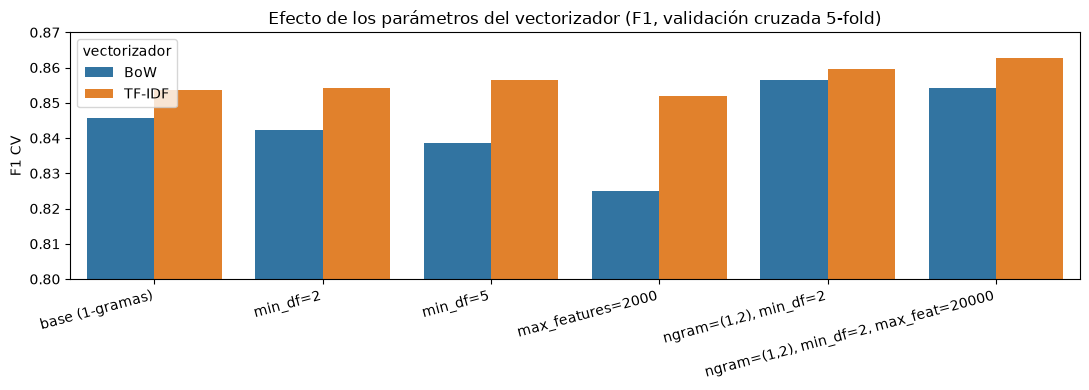

,vectorizador,configuración,vocabulario,exactitud CV,F1 CV
4,BoW,"ngram=(1,2), min_df=2",59645,0.8547,0.8564
11,TF-IDF,"ngram=(1,2), min_df=2, max_feat=20000",20000,0.8605,0.8628


In [21]:
fig, ax = plt.subplots(figsize=(11, 4))
sns.barplot(data=experimentos, x='configuración', y='F1 CV', hue='vectorizador', ax=ax)
ax.set_ylim(0.80, 0.87)
ax.set_title('Efecto de los parámetros del vectorizador (F1, validación cruzada 5-fold)')
ax.set_xlabel('')
plt.xticks(rotation=15, ha='right')
plt.tight_layout()
plt.show()

mejores = experimentos.loc[experimentos.groupby('vectorizador')['F1 CV'].idxmax()]
mejores.round(4)

### Experimentos con parámetros (registro de resultados)

Cada configuración se evaluó con validación cruzada de 5 particiones **sobre el conjunto de entrenamiento**, para no elegir parámetros mirando el conjunto de prueba.

- **TF-IDF supera a BoW en todas las configuraciones.** Con los parámetros por defecto, TF-IDF obtiene un F1 de 0.8537 frente a 0.8456 de BoW. La ponderación IDF y la normalización evitan que las palabras genéricas y las reseñas largas dominen.
- **`min_df`** reduce mucho el vocabulario: de 23 273 a 13 031 términos con `min_df=2`, y a 6 927 con `min_df=5`. En **TF-IDF el rendimiento incluso sube** (F1 0.8537 → 0.8564 con `min_df=5`), porque se eliminan nombres propios y palabras rarísimas a las que TF-IDF daba demasiado peso. En **BoW baja levemente** (0.8456 → 0.8385).
- **`max_features=2000`** recorta demasiado: es la **peor configuración** en ambos vectorizadores (BoW 0.8250, TF-IDF 0.8519). Con solo 2 000 palabras se pierden términos útiles.
- **`ngram_range=(1,2)`** es el parámetro que **más mejora** ambos modelos. Agrega pares de palabras como `wast time`, `must see` o `not good`, que capturan expresiones y negaciones. Con `min_df=2`, el vocabulario sube a 59 645 términos.
- La **mejor configuración de TF-IDF** combina bigramas, `min_df=2` y `max_features=20000` (F1 = 0.8628). Limitar el vocabulario a los 20 000 términos más frecuentes elimina bigramas poco útiles. La **mejor de BoW** es bigramas con `min_df=2` (F1 = 0.8564).

## 5. ENTRENAMIENTO Y EVALUACION

In [22]:
cfg_A = configs[mejores.set_index('vectorizador').loc['BoW', 'configuración']]
cfg_B = configs[mejores.set_index('vectorizador').loc['TF-IDF', 'configuración']]
print('Modelo A (BoW)    ->', cfg_A)
print('Modelo B (TF-IDF) ->', cfg_B)

modelos = {
    'A: BoW + LogReg'   : (CountVectorizer(**cfg_A), LogisticRegression(max_iter=1000)),
    'B: TF-IDF + LogReg': (TfidfVectorizer(**cfg_B), LogisticRegression(max_iter=1000)),
}

resultados, predicciones, entrenados = {}, {}, {}
for nombre, (vec, clf) in modelos.items():
    Xtr = vec.fit_transform(X_train)     # fit solo con train
    Xte = vec.transform(X_test)          # test solo se transforma
    clf.fit(Xtr, y_train)                # entrenar
    y_pred = clf.predict(Xte)            # predecir sobre test
    predicciones[nombre] = y_pred
    entrenados[nombre] = (vec, clf)
    resultados[nombre] = {
        'Exactitud (train)': accuracy_score(y_train, clf.predict(Xtr)),
        'Exactitud': accuracy_score(y_test, y_pred),
        'Precisión': precision_score(y_test, y_pred),
        'Recall':    recall_score(y_test, y_pred),
        'F1':        f1_score(y_test, y_pred),
    }
    print(f'\n===== {nombre} =====')
    print(classification_report(y_test, y_pred, target_names=['negative', 'positive'], digits=4))

Modelo A (BoW)    -> {'ngram_range': (1, 2), 'min_df': 2}
Modelo B (TF-IDF) -> {'ngram_range': (1, 2), 'min_df': 2, 'max_features': 20000}

===== A: BoW + LogReg =====
              precision    recall  f1-score   support

    negative     0.8638    0.8500    0.8569       500
    positive     0.8524    0.8660    0.8591       500

    accuracy                         0.8580      1000
   macro avg     0.8581    0.8580    0.8580      1000
weighted avg     0.8581    0.8580    0.8580      1000


===== B: TF-IDF + LogReg =====
              precision    recall  f1-score   support

    negative     0.8799    0.8500    0.8647       500
    positive     0.8549    0.8840    0.8692       500

    accuracy                         0.8670      1000
   macro avg     0.8674    0.8670    0.8670      1000
weighted avg     0.8674    0.8670    0.8670      1000



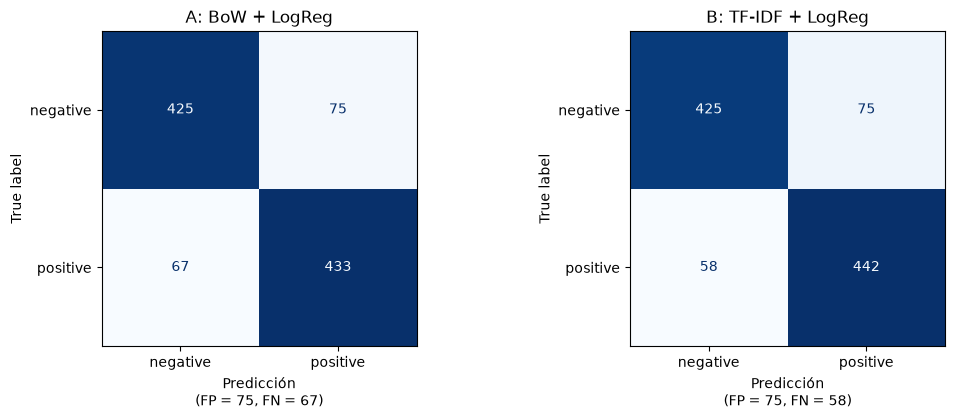

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.3))
for ax, (nombre, y_pred) in zip(axes, predicciones.items()):
    cm = confusion_matrix(y_test, y_pred)
    ConfusionMatrixDisplay(cm, display_labels=['negative', 'positive']).plot(
        ax=ax, cmap='Blues', colorbar=False)
    tn, fp, fn, tp = cm.ravel()
    ax.set_title(nombre)
    ax.set_xlabel(f'Predicción\n(FP = {fp}, FN = {fn})')
plt.tight_layout()
plt.show()

In [24]:
tabla = pd.DataFrame(resultados).T
tabla.round(4)

,Exactitud (train),Exactitud,Precisión,Recall,F1
A: BoW + LogReg,1.000,0.858,0.8524,0.866,0.8591
B: TF-IDF + LogReg,0.958,0.867,0.8549,0.884,0.8692


### Resultados y elección del modelo

| Modelo | Exactitud (train) | Exactitud | Precisión | Recall | F1 | FP | FN |
|---|---|---|---|---|---|---|---|
| A: BoW + LogReg | 1.000 | 0.858 | 0.8524 | 0.866 | 0.8591 | 75 | 67 |
| B: TF-IDF + LogReg | 0.958 | **0.867** | **0.8549** | **0.884** | **0.8692** | 75 | **58** |

**Se elige el Modelo B: TF-IDF + Regresión Logística** (unigramas y bigramas, `min_df=2`, `max_features=20000`), porque:

1. **Es mejor en todas las métricas del conjunto de prueba:** exactitud 0.867 frente a 0.858, y F1 0.8692 frente a 0.8591. Esto coincide con lo que ya indicaba la validación cruzada del In [4], así que no es suerte de una partición en particular.
2. **Comete menos errores:** 133 frente a 142. Ambos modelos tienen los mismos 75 falsos positivos, pero B tiene menos falsos negativos (58 frente a 67), es decir, reconoce mejor las reseñas positivas. Por eso su recall es más alto.
3. **Sobreajusta menos:** BoW llega al **100 % de exactitud en entrenamiento**, lo que indica que memorizó los datos, y luego baja a 85.8 % en prueba. TF-IDF se queda en 95.8 % en entrenamiento y tiene una brecha train–test menor.

**Observación:** en ambos modelos hay más falsos positivos que falsos negativos, así que tienden a clasificar como positivas algunas reseñas negativas. La diferencia es moderada.

Como el dataset está balanceado, la exactitud es una métrica confiable, y el F1 confirma la misma conclusión.

## Escalado al dataset completo (~49 600 reseñas)

In [25]:
t0 = time.time()
df['label'] = (df['sentiment'] == 'positive').astype(int)
df['clean'] = df['review'].apply(preprocesar)
print(f'Versión sin negaciones: {time.time() - t0:.0f} s')

df['clean_sw_nltk'] = df['review'].apply(lambda x: preprocesar(x, stop=sw_nltk))
print(f'Total (2 versiones): {time.time() - t0:.0f} s')

Versión sin negaciones: 270 s
Total (2 versiones): 565 s


In [26]:
Xf_train, Xf_test, yf_train, yf_test, idx_train, idx_test = train_test_split(
    df['clean'], df['label'], df.index,
    test_size=0.2, stratify=df['label'], random_state=SEED)
print(f'Entrenamiento: {len(Xf_train)} | Prueba: {len(Xf_test)}')

filas_full = {}
for nombre, Vec, cfg in [('A: BoW + LogReg', CountVectorizer, cfg_A),
                         ('B: TF-IDF + LogReg', TfidfVectorizer, cfg_B)]:
    vec = Vec(**cfg)
    clf = LogisticRegression(max_iter=1000)
    clf.fit(vec.fit_transform(Xf_train), yf_train)
    yp = clf.predict(vec.transform(Xf_test))
    filas_full[nombre] = {'Exactitud': accuracy_score(yf_test, yp),
                          'Precisión': precision_score(yf_test, yp),
                          'Recall': recall_score(yf_test, yp),
                          'F1': f1_score(yf_test, yp)}
    if nombre == 'B: TF-IDF + LogReg':
        mejor_vec, mejor_clf, yf_pred = vec, clf, yp

comp = pd.concat({'Muestra 5 000': tabla[['Exactitud', 'Precisión', 'Recall', 'F1']],
                  'Completo': pd.DataFrame(filas_full).T})
comp.round(4)

Entrenamiento: 39665 | Prueba: 9917


Exactitud  Precisión  Recall      F1
Muestra 5 000 A: BoW + LogReg        0.8580     0.8524  0.8660  0.8591
              B: TF-IDF + LogReg     0.8670     0.8549  0.8840  0.8692
Completo      A: BoW + LogReg        0.9049     0.9013  0.9102  0.9057
              B: TF-IDF + LogReg     0.9032     0.8944  0.9152  0.9047

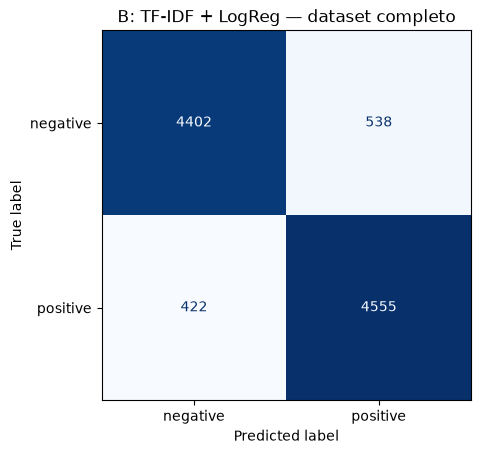

In [27]:
ConfusionMatrixDisplay(confusion_matrix(yf_test, yf_pred),
                       display_labels=['negative', 'positive']).plot(cmap='Blues', colorbar=False)
plt.title('B: TF-IDF + LogReg — dataset completo')
plt.show()

In [28]:
filas_sw = {}
for ngram in [(1, 1), (1, 2)]:
    for nombre_sw, col in [('Stopwords NLTK completas', 'clean_sw_nltk'),
                           ('Sin negaciones (elegido)', 'clean')]:
        vec = TfidfVectorizer(ngram_range=ngram, min_df=2)
        clf = LogisticRegression(max_iter=1000)
        clf.fit(vec.fit_transform(df.loc[idx_train, col]), yf_train)
        yp = clf.predict(vec.transform(df.loc[idx_test, col]))
        filas_sw[(f'ngram={ngram}', nombre_sw)] = {'Exactitud': accuracy_score(yf_test, yp),
                                                   'F1': f1_score(yf_test, yp)}
pd.DataFrame(filas_sw).T.round(4)

Exactitud      F1
ngram=(1, 1) Stopwords NLTK completas     0.8946  0.8966
             Sin negaciones (elegido)     0.8933  0.8950
ngram=(1, 2) Stopwords NLTK completas     0.8964  0.8987
             Sin negaciones (elegido)     0.8993  0.9010

### Resultados del escalado

| Datos | Modelo | Exactitud | Precisión | Recall | F1 |
|---|---|---|---|---|---|
| Muestra 5 000 | A: BoW | 0.8580 | 0.8524 | 0.8660 | 0.8591 |
| Muestra 5 000 | B: TF-IDF | 0.8670 | 0.8549 | 0.8840 | 0.8692 |
| Completo (~49 600) | A: BoW | 0.9049 | 0.9013 | 0.9102 | 0.9057 |
| Completo (~49 600) | B: TF-IDF | 0.9032 | 0.8944 | 0.9152 | 0.9047 |

**Más datos mejoran claramente el modelo:** la exactitud sube de ~86-87 % a ~90 % (unos 4 puntos). Con 5 000 reseñas, muchos bigramas útiles aparecen pocas veces. Con 39 665 reseñas de entrenamiento, el modelo ve suficientes ejemplos de cada expresión para estimar bien su coeficiente.

**Observación importante:** con el dataset completo, los dos modelos quedan **prácticamente empatados** (diferencia de 0.17 puntos, a favor de BoW). La ventaja de TF-IDF se nota sobre todo **cuando hay pocos datos**. Además, la configuración de B se eligió con la muestra (`max_features=20000`), y con ~40 000 reseñas ese límite podría dejar fuera bigramas útiles. Se mantiene el **modelo B** para la interpretación porque fue el elegido con la metodología correcta (validación cruzada), pero la conclusión honesta es que con el dataset completo ambas representaciones rinden igual.

### Verificación de las stopwords con el dataset completo

| Configuración | Stopwords | Exactitud | F1 |
|---|---|---|---|
| Unigramas (1,1) | NLTK completas | 0.8946 | 0.8966 |
| Unigramas (1,1) | Sin negaciones (elegido) | 0.8933 | 0.8950 |
| Bigramas (1,2) | NLTK completas | 0.8964 | 0.8987 |
| Bigramas (1,2) | **Sin negaciones (elegido)** | **0.8993** | **0.9010** |

Con suficientes datos aparece el efecto que predecía el análisis del In [2]:

- Con **unigramas**, conservar las negaciones **no ayuda** (incluso baja 0.13 puntos). Un `not` suelto no indica a qué palabra niega, así que solo agrega ruido.
- Con **bigramas**, conservar las negaciones es **la mejor configuración de todas** (89.93 %). El modelo puede aprender combinaciones como `not good` o `not bad`, que serían imposibles si `not` se eliminara.

Esto **confirma la decisión del In [2]**: en análisis de sentimiento, las negaciones son información, siempre que se usen junto con bigramas.

## 6. INTERPRETACION DEL MODELO

15 más POSITIVAS             15 más NEGATIVAS            
            término coeficiente          término coeficiente
0             great       7.578            worst      -9.174
1             excel       6.980               aw      -8.062
2           perfect       5.505              bad      -7.932
3             enjoy       5.372             wast      -7.187
4              love       5.044             bore      -7.095
5              best       4.821             poor      -6.153
6              amaz       4.737          terribl      -5.842
7         brilliant       4.416       disappoint      -5.838
8           favorit       4.383             noth      -5.288
9               fun       4.330             fail      -5.144
10         one best       4.195          horribl      -4.961
11           hilari       4.091             wors      -4.730
12           beauti       4.035             dull      -4.645
13            today       4.029           stupid      -4.558
14         must see       3.954           poorli      -4.404

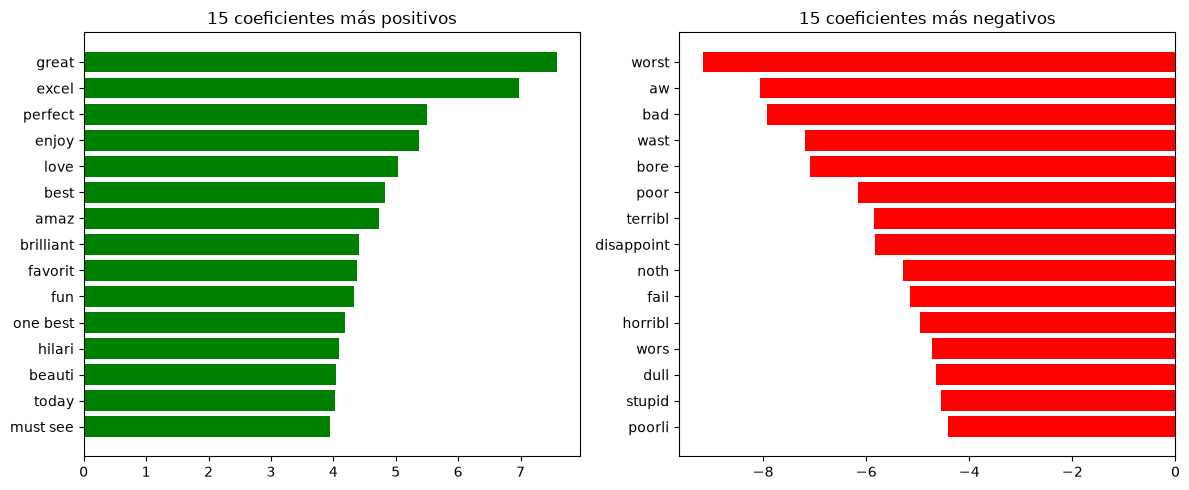

In [29]:
terminos = np.array(mejor_vec.get_feature_names_out())
coef = mejor_clf.coef_[0]
orden = np.argsort(coef)

top_pos = pd.DataFrame({'término': terminos[orden[-15:][::-1]],
                        'coeficiente': coef[orden[-15:][::-1]].round(3)})
top_neg = pd.DataFrame({'término': terminos[orden[:15]],
                        'coeficiente': coef[orden[:15]].round(3)})
display(pd.concat({'15 más POSITIVAS': top_pos, '15 más NEGATIVAS': top_neg}, axis=1))

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].barh(top_pos['término'][::-1], top_pos['coeficiente'][::-1], color='green')
axes[0].set_title('15 coeficientes más positivos')
axes[1].barh(top_neg['término'][::-1], top_neg['coeficiente'][::-1], color='red')
axes[1].set_title('15 coeficientes más negativos')
plt.tight_layout()
plt.show()

In [30]:
for t in ['good', 'not good', 'bad', 'not bad', 'recommend', 'not recommend',
          'funni', 'not funni', 'wast', 'not wast']:
    if t in mejor_vec.vocabulary_:
        print(f'{t:15s} {coef[mejor_vec.vocabulary_[t]]:+.3f}')

good            +2.683
not good        -3.591
bad             -7.932
not bad         +1.154
recommend       +2.945
not recommend   -3.719
funni           +1.536
not funni       -4.061
wast            -7.187
not wast        -1.260


**¿Tienen sentido las palabras?** Sí, claramente:

- **Positivas:** adjetivos de elogio (`great`, `excel`, `perfect`, `enjoy`, `love`, `best`, `amaz`, `brilliant`, `favorit`, `fun`, `hilari`, `beauti`) y dos **bigramas**: `one best` (*"one of the best"*, porque `of` y `the` se eliminaron como stopwords) y `must see`. Estos bigramas solo existen gracias a `ngram_range=(1,2)`.
- **Negativas:** `worst` (el coeficiente más fuerte de todo el modelo, −9.17), `aw` (*awful*), `bad`, `wast` (*waste*, como en "waste of time"), `bore`, `poor`, `terribl`, `disappoint`, `noth` (*nothing*), `fail`, `horribl`, `wors`, `dull`, `stupid`, `poorli`. Es el vocabulario típico de una crítica negativa.
- Hay un término menos obvio: **`today`**. Por sí solo no expresa sentimiento, pero tiene sentido como patrón de uso ("one of the best films made **today**", "still holds up **today**"). El modelo aprende asociaciones estadísticas del contexto en que aparece cada palabra.
- Las palabras negativas tienen coeficientes **más fuertes** que las positivas (−9.17 frente a 7.58 en el extremo). Un solo "worst" pesa más que un "great".

### ¿Aprendió el modelo la negación?

| Palabra | Coeficiente | Con `not` | Coeficiente |
|---|---|---|---|
| good | +2.683 | not good | **−3.591** |
| bad | −7.932 | not bad | **+1.154** |
| recommend | +2.945 | not recommend | **−3.719** |
| funni | +1.536 | not funni | **−4.061** |
| wast | −7.187 | not wast | −1.260 |

**Sí.** El modelo aprendió que `not` **invierte** el sentido de la palabra siguiente: `good` es positivo pero `not good` es negativo, y `bad` es muy negativo pero **`not bad` es positivo** (el uso típico es "not bad at all"). En el caso de `not wast` no llega a ser positivo, pero pasa de −7.19 a −1.26, mucho menos negativo.

Esta es la **prueba más clara** de que la decisión del In [2] fue correcta: si se hubiera eliminado `not` con la lista completa de NLTK, estos bigramas no existirían y el modelo trataría "not good" igual que "good".

In [31]:
mis_resenas = {
    'Claramente positiva': "This movie was absolutely wonderful. The acting was brilliant, the story moved me "
                           "and the soundtrack is beautiful. One of the best films I have seen this year, highly recommended!",
    'Claramente negativa': "A boring and terrible film. The plot makes no sense, the dialogue is awful and the "
                           "actors look like they don't care. A complete waste of time and money.",
    'Ambigua / sarcástica': "Oh great, another two hours of my life I will never get back. "
                            "Truly a masterpiece of boredom, I loved checking my watch every five minutes.",
}

filas = []
for tipo, texto in mis_resenas.items():
    v = mejor_vec.transform([preprocesar(texto)])
    p = mejor_clf.predict_proba(v)[0]
    filas.append({'tipo': tipo,
                  'predicción': 'positive' if p[1] >= 0.5 else 'negative',
                  'P(negative)': round(p[0], 3),
                  'P(positive)': round(p[1], 3)})
pd.DataFrame(filas)

,tipo,predicción,P(negative),P(positive)
0,Claramente positiva,positive,0.001,0.999
1,Claramente negativa,negative,1.000,0.000
2,Ambigua / sarcástica,negative,0.523,0.477


In [32]:
def contribuciones(texto_limpio, k=6):
    v = mejor_vec.transform([texto_limpio]).toarray().ravel()
    c = v * coef                       # aporte de cada término = valor TF-IDF x coeficiente
    idx = np.nonzero(c)[0]
    idx = idx[np.argsort(c[idx])]
    neg = [(terminos[j], round(float(c[j]), 3)) for j in idx[:k] if c[j] < 0]
    pos = [(terminos[j], round(float(c[j]), 3)) for j in idx[::-1][:k] if c[j] > 0]
    return pos, neg

for tipo, texto in mis_resenas.items():
    pos, neg = contribuciones(preprocesar(texto))
    print(f'{tipo}\n  empujan a POSITIVE: {pos}\n  empujan a NEGATIVE: {neg}\n')

Claramente positiva
  empujan a POSITIVE: [('brilliant', 0.867), ('one best', 0.854), ('highli recommend', 0.785), ('beauti', 0.629), ('best', 0.598), ('highli', 0.571)]
  empujan a NEGATIVE: [('act', -0.23), ('movi', -0.056), ('movi absolut', -0.052), ('absolut', -0.011)]

Claramente negativa
  empujan a POSITIVE: [('like not', 0.208), ('time', 0.132), ('film plot', 0.084), ('film', 0.042), ('sens', 0.016), ('like', 0.004)]
  empujan a NEGATIVE: [('aw', -1.271), ('wast', -1.08), ('bore', -1.029), ('terribl', -0.919), ('wast time', -0.693), ('look like', -0.45)]

Ambigua / sarcástica
  empujan a POSITIVE: [('great', 0.805), ('love', 0.553), ('masterpiec', 0.42), ('truli', 0.309), ('life', 0.294), ('watch everi', 0.199)]
  empujan a NEGATIVE: [('oh', -0.655), ('minut', -0.527), ('boredom', -0.427), ('hour', -0.28), ('two hour', -0.272), ('hour life', -0.23)]



### 6.2 Reseñas propias

| Tipo | Predicción | P(negative) | P(positive) |
|---|---|---|---|
| Claramente positiva | positive | 0.001 | **0.999** |
| Claramente negativa | negative | **1.000** | 0.000 |
| Ambigua / sarcástica | negative | 0.523 | 0.477 |

- La **positiva** y la **negativa** se clasifican correctamente y con una seguridad casi total, porque contienen exactamente el vocabulario que el modelo asocia a cada clase (`brilliant`, `best`, `beauti`, `highli recommend` frente a `bore`, `terribl`, `aw`, `wast time`).
- La **sarcástica** es el caso interesante. Para una persona es claramente negativa ("dos horas de mi vida que nunca recuperaré", "una obra maestra del aburrimiento"), pero está construida con palabras **positivas** (`great`, `love`, `masterpiec`, `truli`). El modelo la clasificó como negativa **por muy poco** (P = 0.523, casi 50/50). Lo que la inclinó fueron palabras como `oh` (la de mayor peso negativo), `minut`, `boredom` y `two hour`. Curiosamente, "oh" se usa mucho en reseñas negativas con tono irónico ("oh, please"), así que el modelo captó algo del sarcasmo **por casualidad estadística**, no porque lo entendiera.
- El modelo **no entendió el sarcasmo**: solo ve qué palabras aparecen, no el tono ni la intención. Las fuerzas positivas y negativas casi se anularon. Es una limitación conocida de Bag of Words / TF-IDF: el sarcasmo depende del contraste entre lo que se dice y lo que se quiere decir, y eso requiere entender el contexto.

In [33]:
X_eval, y_eval, y_eval_pred = Xf_test, yf_test.values, yf_pred
textos_test_orig = df.loc[idx_test, 'review'].values

proba_eval = mejor_clf.predict_proba(mejor_vec.transform(X_eval))[:, 1]
errores = np.where(y_eval != y_eval_pred)[0]
print(f'Mal clasificadas: {len(errores)} de {len(y_eval)} ({len(errores)/len(y_eval)*100:.1f} %)')

fp = [i for i in errores if y_eval[i] == 0]   # real negativa, predicha positiva
fn = [i for i in errores if y_eval[i] == 1]   # real positiva, predicha negativa
i_fp = max(fp, key=lambda i: proba_eval[i])   # el FP con más confianza
i_fn = min(fn, key=lambda i: proba_eval[i])   # el FN con más confianza

for etiqueta, i in [('FALSO POSITIVO (real: negative)', i_fp),
                    ('FALSO NEGATIVO (real: positive)', i_fn)]:
    pos, neg = contribuciones(X_eval.iloc[i])
    print('\n' + '=' * 90)
    print(f'{etiqueta} | P(positive) = {proba_eval[i]:.3f}')
    print('=' * 90)
    print(re.sub(r'<br\s*/?>', ' ', textos_test_orig[i])[:2500])
    print(f'\n  Empujaron a POSITIVE: {pos}')
    print(f'  Empujaron a NEGATIVE: {neg}')

Mal clasificadas: 960 de 9917 (9.7 %)

FALSO POSITIVO (real: negative) | P(positive) = 0.975
this one of the best celebrity's reality shows a ever saw. we can see the concerts we can see the life of Britney, i love the five episodes. i was always being surprised by Britney and the subjects of the show i think that some people don't watch the show at all we can how a great person she his. she his really funny really gentle and she loves her fans and we can see how she loves her work. i just don't give a 10 because of k-fed he his a real jerk he doesn't seem to like Britney at all. I they make a second season of this great show because it shows at some people how Britney really is. Go Britney your the best and you will never leave our hearts.

  Empujaron a POSITIVE: [('love', 0.631), ('great', 0.612), ('best', 0.435), ('one best', 0.31), ('see', 0.266), ('surpris', 0.212)]
  Empujaron a NEGATIVE: [('not', -0.229), ('britney', -0.21), ('seem', -0.102), ('seem like', -0.076), ('jerk', -0.

### 6.3 Reseñas del conjunto de prueba mal clasificadas

El modelo final se equivocó en **960 de 9 917 reseñas (9.7 %)**. Se eligieron **un falso positivo y un falso negativo**: los dos errores en los que el modelo estuvo **más seguro**.

**Falso positivo: reseña del reality show de Britney Spears** (etiqueta real: *negative*, P(positive) = 0.975)

Al leerla, la reseña es claramente **positiva**: "one of the best celebrity's reality shows I ever saw", "I love the five episodes", "this great show", "Go Britney your the best". Lo único negativo es que el autor no le pone un 10 por culpa de K-Fed ("a real jerk"). El modelo detectó correctamente `love`, `great`, `best` y `one best`. **El modelo acertó y la etiqueta del dataset está mal.**

**Falso negativo: reseña de una película europea sobre estudiantes Erasmus** (etiqueta real: *positive*, P(positive) = 0.009)

Ocurre lo mismo al revés. El texto es una crítica dura: "such a disappointment", "full of (silly) clichés", "pretty insulting", "the acting was pretty horrible", "the content pretty horrible". Solo elogia aspectos técnicos y la banda sonora. El modelo la clasificó como negativa por `bad`, `horribl` y `disappoint`, con toda razón. **De nuevo, la etiqueta parece incorrecta.**

**¿Por qué "falló" el modelo?** En estos dos casos no falló: el problema es **ruido en las etiquetas**. El dataset se construyó a partir de la nota numérica que puso cada usuario, y a veces esa nota no coincide con lo que escribió (por error al calificar o al recopilar los datos).

**Conclusiones del análisis de errores:**
- Los errores en los que el modelo está **más seguro** pueden ser en realidad **errores del dataset**. Por eso, la exactitud real del modelo probablemente es algo mayor que el 90.3 % medido.
- Esto también marca un **límite**: ningún modelo puede superar cierta exactitud si una parte de las etiquetas está mal.
- Los errores **genuinos** del modelo suelen estar cerca de P ≈ 0.5, como pasó con la reseña sarcástica del 6.2: reseñas con sarcasmo, con opiniones mixtas ("great cast, but...") o que describen una trama oscura con palabras negativas aunque la película les haya gustado. En esos casos, la representación BoW/TF-IDF pierde el **orden y el contexto** de las palabras.

## Conclusiones

1. **El flujo de clase funciona para sentimiento, pero había que adaptarlo.** Las adaptaciones clave fueron: eliminar `<br />` (presente en el 58 % de las reseñas), expandir las contracciones negativas (`didn't → did not`) y **no eliminar** las negaciones (`not`, `no`, `but`) de las stopwords.
2. **Exploración:** el dataset está balanceado, no tiene valores nulos, y se eliminaron 418 reseñas duplicadas para evitar fuga de datos. La longitud de la reseña no sirve para distinguir el sentimiento.
3. **Negaciones:** con la muestra de 5 000 reseñas su efecto no fue medible, pero con el dataset completo y bigramas, conservarlas fue la mejor configuración (89.93 %). El modelo aprendió que `not bad` es positivo (+1.15) y `not good` negativo (−3.59).
4. **Vectorización:** con la muestra, **TF-IDF superó a BoW** en todas las configuraciones. Los **bigramas** fueron el parámetro que más ayudó (`one best`, `must see`), `min_df` redujo mucho el vocabulario sin perder rendimiento, y recortar demasiado con `max_features=2000` empeoró el modelo.
5. **Modelo elegido:** TF-IDF con unigramas y bigramas + Regresión Logística. Alcanzó **86.7 % de exactitud con 5 000 reseñas** y **90.3 % con el dataset completo**. Con todos los datos, BoW y TF-IDF quedaron prácticamente empatados: la ventaja de TF-IDF se nota sobre todo con pocos datos.
6. **El modelo es interpretable:** las palabras con mayor coeficiente coinciden con la intuición humana (`great`, `excel`, `perfect` frente a `worst`, `aw`, `bad`).
7. **Análisis de errores:** los errores más "seguros" del modelo resultaron ser **etiquetas incorrectas del dataset**, no fallos del modelo. Los errores genuinos aparecen en el sarcasmo y en las opiniones mixtas.
8. **Limitaciones y trabajo futuro:** la representación ignora el orden y el contexto de las palabras, por eso el sarcasmo es difícil. Como mejoras se podría ajustar la regularización `C` de la regresión logística, recalibrar `max_features` con el dataset completo o usar modelos que entienden el contexto (embeddings o modelos tipo BERT).